# Results viewer: Feng et al., *Attribute Inference Attack of SER in Federated Learning*

This notebook loads the saved results in `../results/` (no training is re-run) and compares them with the paper.

* **Main setting (paper protocol):** `speaker_norm`, within-speaker z-normalisation of emobase features
* **Extra setting:** `global_norm`, z-normalisation with training-set statistics
* **Supplementary:** `indomain_probe.csv`, a speaker-disjoint, same-corpus linear probe

Corpus substitutes: EmoDB ↔ IEMOCAP, RAVDESS ↔ MSP-Improv, CREMA-D ↔ CREMA-D.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RES = Path('../results')
NORMS, MODES, DPS = ['speaker', 'global'], ['fed_sgd', 'fed_avg'], ['emodb', 'crema-d', 'ravdess']
NAME = {'crema-d': 'CREMA-D', 'emodb': 'EmoDB', 'ravdess': 'RAVDESS'}
MODE = {'fed_sgd': 'FedSGD', 'fed_avg': 'FedAvg'}
SUBST = {'crema-d': 'CREMA-D', 'emodb': 'IEMOCAP', 'ravdess': 'MSP-Improv'}
LAYERS = ['first', 'second', 'last']

# paper numbers (emobase rows)
PAPER_SER_UAR = {'fed_sgd': {'IEMOCAP': 61.62, 'CREMA-D': 64.24, 'MSP-Improv': 47.23},
                 'fed_avg': {'IEMOCAP': 61.25, 'CREMA-D': 66.38, 'MSP-Improv': 47.67}}
PAPER_ATTACK = {  # layer-wise attack success rate, Table 5 (emobase)
    'fed_sgd': {'IEMOCAP': [89.35, 60.22, 57.90], 'CREMA-D': [73.82, 59.91, 58.02], 'MSP-Improv': [91.34, 60.22, 56.24]},
    'fed_avg': {'IEMOCAP': [87.38, 59.20, 55.27], 'CREMA-D': [81.78, 59.28, 56.12], 'MSP-Improv': [83.08, 52.33, 52.13]}}
pd.options.display.float_format = '{:.2f}'.format

## 1. Load all per-fold results

In [2]:
rows = []
for norm in NORMS:
    for mode in MODES:
        for dp in DPS:
            f = RES / f'{norm}_norm' / mode / dp / 'private_results.csv'
            if not f.exists():
                continue
            d = pd.read_csv(f)
            d = d[d.fold != 'average'].copy()
            d['norm'], d['mode'], d['dp'] = norm, mode, dp
            rows.append(d)
folds = pd.concat(rows, ignore_index=True)
num = [c for c in folds.columns if c.startswith(('ser_', 'attack_'))]
folds[num] = folds[num] * 100
avg = folds.groupby(['norm', 'mode', 'dp'], sort=False)[num].agg(['mean', 'std'])
print(len(folds), 'fold results loaded')
folds.head()

60 fold results loaded


,fold,n_updates,ser_acc,ser_uar,attack_first_acc,attack_first_uar,attack_first_client_asr,attack_second_acc,attack_second_uar,attack_second_client_asr,attack_last_acc,attack_last_uar,attack_last_client_asr,norm,mode,dp
0,1,400.00,91.36,91.33,51.25,49.35,50.32,53.50,50.18,51.10,53.50,50.30,51.09,speaker,fed_sgd,emodb
1,2,400.00,84.31,78.55,48.00,46.20,45.98,49.50,46.75,47.25,51.00,48.19,48.54,speaker,fed_sgd,emodb
2,3,400.00,78.95,81.88,49.25,44.11,48.58,55.25,46.17,56.12,58.25,49.21,58.99,speaker,fed_sgd,emodb
3,4,400.00,80.52,80.87,40.00,47.77,40.36,36.75,49.05,38.96,38.50,51.27,41.02,speaker,fed_sgd,emodb
4,5,400.00,84.93,84.37,43.50,45.77,43.89,46.25,50.24,49.58,46.50,50.23,50.10,speaker,fed_sgd,emodb


## 2. Federated SER performance vs the paper (UAR %)

In [3]:
t = []
for (norm, mode, dp), r in avg.iterrows():
    t.append({'norm': norm, 'FL': MODE[mode], 'D_p (ours)': NAME[dp], 'paper corpus': SUBST[dp],
              'ours UAR': r[('ser_uar', 'mean')], '± std': r[('ser_uar', 'std')],
              'paper UAR': PAPER_SER_UAR[mode][SUBST[dp]]})
ser = pd.DataFrame(t)
ser

,norm,FL,D_p (ours),paper corpus,ours UAR,± std,paper UAR
0,speaker,FedSGD,EmoDB,IEMOCAP,83.40,4.90,61.62
1,speaker,FedSGD,CREMA-D,CREMA-D,76.81,2.86,64.24
2,speaker,FedSGD,RAVDESS,MSP-Improv,70.97,4.41,47.23
3,speaker,FedAvg,EmoDB,IEMOCAP,86.90,3.72,61.25
4,speaker,FedAvg,CREMA-D,CREMA-D,79.04,2.87,66.38
5,speaker,FedAvg,RAVDESS,MSP-Improv,69.38,5.17,47.67
6,global,FedSGD,EmoDB,IEMOCAP,78.95,6.58,61.62
7,global,FedSGD,CREMA-D,CREMA-D,68.17,2.67,64.24
8,global,FedSGD,RAVDESS,MSP-Improv,62.06,7.29,47.23
9,global,FedAvg,EmoDB,IEMOCAP,81.30,9.39,61.25


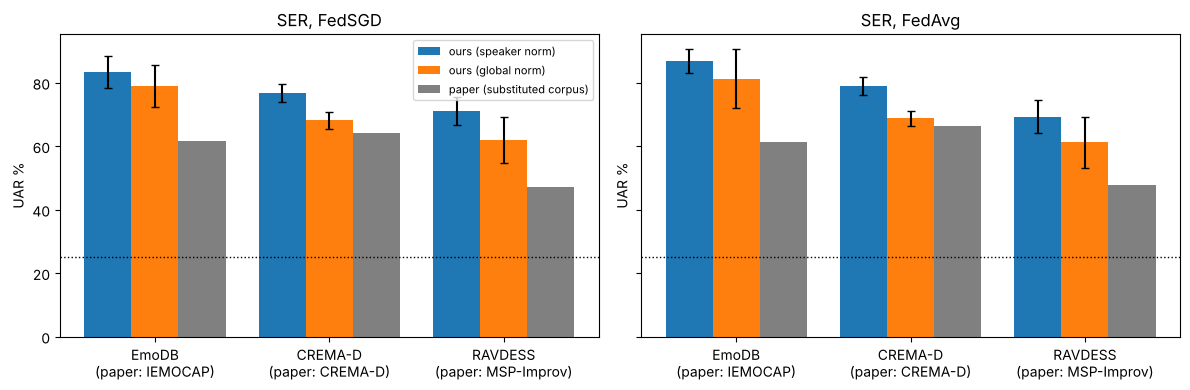

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, mode in zip(axes, MODES):
    x = np.arange(len(DPS)); w = 0.27
    for i, norm in enumerate(NORMS):
        s = ser[(ser.norm == norm) & (ser.FL == MODE[mode])].set_index('D_p (ours)').loc[[NAME[d] for d in DPS]]
        ax.bar(x + (i - 1) * w, s['ours UAR'], w, yerr=s['± std'], capsize=3, label=f'ours ({norm} norm)')
    ax.bar(x + w, [PAPER_SER_UAR[mode][SUBST[d]] for d in DPS], w, color='grey', label='paper (substituted corpus)')
    ax.set_xticks(x, [f'{NAME[d]}\n(paper: {SUBST[d]})' for d in DPS])
    ax.set_title(f'SER, {MODE[mode]}'); ax.set_ylabel('UAR %'); ax.axhline(25, ls=':', c='k', lw=1)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 3. Gender inference attack on first-layer updates vs the paper

`client_asr` is the paper's metric: the share of correct predictions per client, averaged over clients.

In [5]:
t = []
for (norm, mode, dp), r in avg.iterrows():
    t.append({'norm': norm, 'FL': MODE[mode], 'D_p': NAME[dp],
              'D_s (shadow)': '+'.join(NAME[d] for d in ['crema-d', 'ravdess', 'emodb'] if d != dp),
              'ours UAR': r[('attack_first_uar', 'mean')], 'ours client ASR': r[('attack_first_client_asr', 'mean')],
              'paper ASR': PAPER_ATTACK[mode][SUBST[dp]][0], 'paper corpus': SUBST[dp]})
att = pd.DataFrame(t)
att

,norm,FL,D_p,D_s (shadow),ours UAR,ours client ASR,paper ASR,paper corpus
0,speaker,FedSGD,EmoDB,CREMA-D+RAVDESS,46.64,45.83,89.35,IEMOCAP
1,speaker,FedSGD,CREMA-D,RAVDESS+EmoDB,45.55,46.64,73.82,CREMA-D
2,speaker,FedSGD,RAVDESS,CREMA-D+EmoDB,51.94,51.99,91.34,MSP-Improv
3,speaker,FedAvg,EmoDB,CREMA-D+RAVDESS,43.22,43.90,87.38,IEMOCAP
4,speaker,FedAvg,CREMA-D,RAVDESS+EmoDB,49.78,52.47,81.78,CREMA-D
5,speaker,FedAvg,RAVDESS,CREMA-D+EmoDB,50.59,50.48,83.08,MSP-Improv
6,global,FedSGD,EmoDB,CREMA-D+RAVDESS,47.37,47.58,89.35,IEMOCAP
7,global,FedSGD,CREMA-D,RAVDESS+EmoDB,54.12,55.27,73.82,CREMA-D
8,global,FedSGD,RAVDESS,CREMA-D+EmoDB,54.77,54.63,91.34,MSP-Improv
9,global,FedAvg,EmoDB,CREMA-D+RAVDESS,55.84,56.76,87.38,IEMOCAP


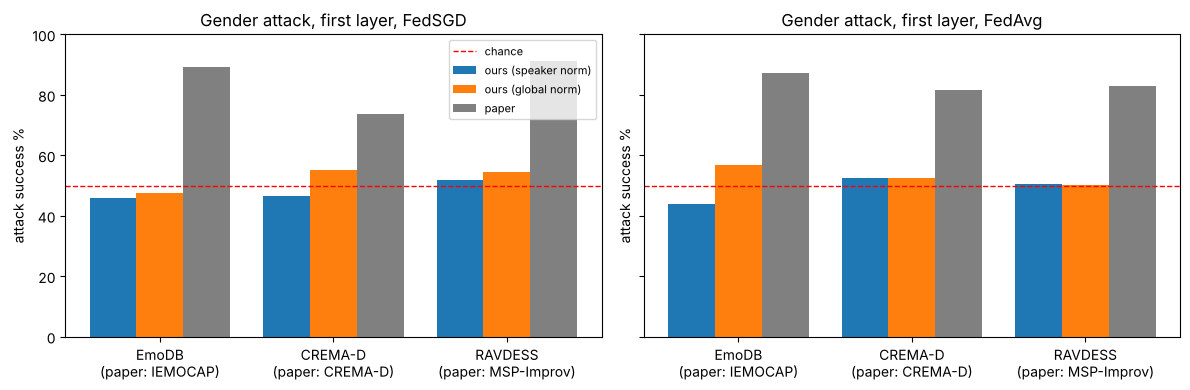

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, mode in zip(axes, MODES):
    x = np.arange(len(DPS)); w = 0.27
    for i, norm in enumerate(NORMS):
        s = att[(att.norm == norm) & (att.FL == MODE[mode])].set_index('D_p').loc[[NAME[d] for d in DPS]]
        ax.bar(x + (i - 1) * w, s['ours client ASR'], w, label=f'ours ({norm} norm)')
    ax.bar(x + w, [PAPER_ATTACK[mode][SUBST[d]][0] for d in DPS], w, color='grey', label='paper')
    ax.axhline(50, ls='--', c='r', lw=1, label='chance')
    ax.set_xticks(x, [f'{NAME[d]}\n(paper: {SUBST[d]})' for d in DPS]); ax.set_ylim(0, 100)
    ax.set_title(f'Gender attack, first layer, {MODE[mode]}'); ax.set_ylabel('attack success %')
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 4. Which layer leaks most?

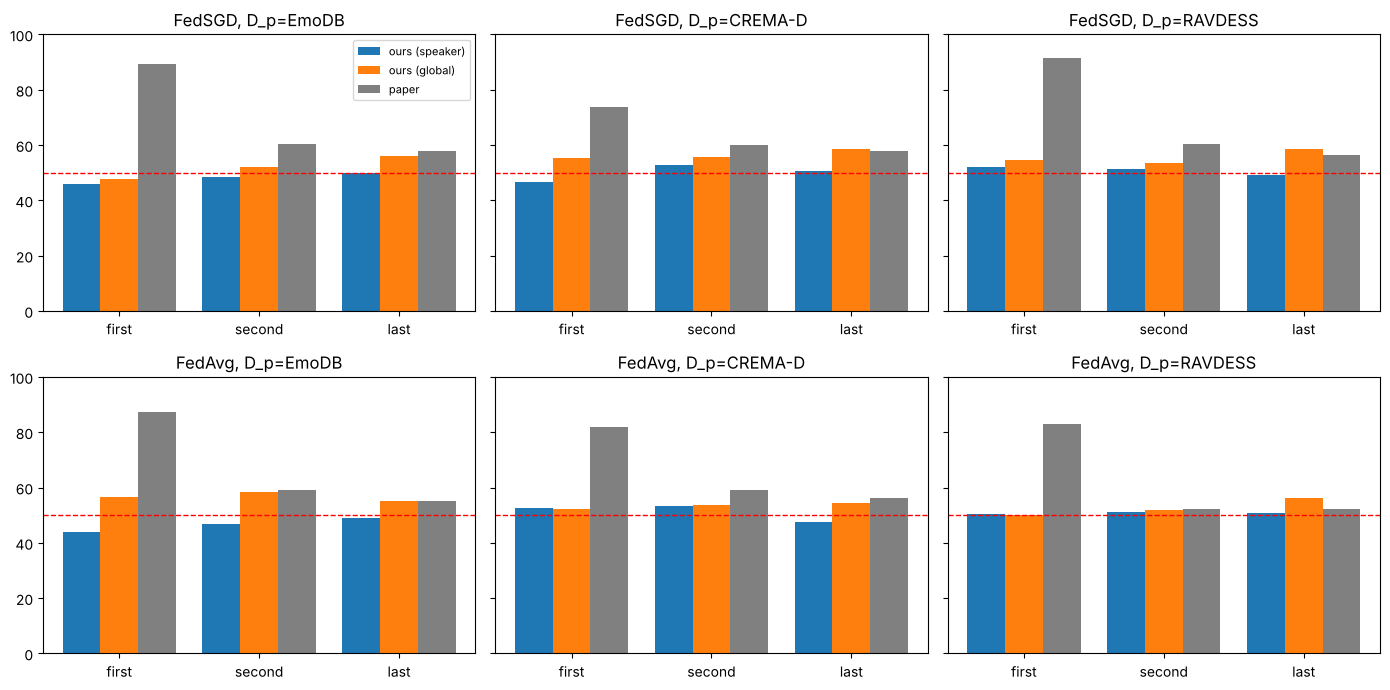

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
for i, mode in enumerate(MODES):
    for j, dp in enumerate(DPS):
        ax = axes[i, j]; x = np.arange(3); w = 0.27
        for k, norm in enumerate(NORMS):
            r = avg.loc[(norm, mode, dp)]
            ax.bar(x + (k - 1) * w, [r[(f'attack_{l}_client_asr', 'mean')] for l in LAYERS], w, label=f'ours ({norm})')
        ax.bar(x + w, PAPER_ATTACK[mode][SUBST[dp]], w, color='grey', label='paper')
        ax.axhline(50, ls='--', c='r', lw=1)
        ax.set_xticks(x, LAYERS); ax.set_ylim(0, 100); ax.set_title(f'{MODE[mode]}, D_p={NAME[dp]}')
axes[0, 0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 5. Attack-model training curves (shadow validation)

The shadow validation split is a random 80/20 split of updates, as in the paper, so the same clients appear on both sides. High validation scores next to near-chance test scores point to client memorisation, not generalisation. The first-layer curves were still rising at epoch 8, our CPU budget; the paper trains about 50 epochs.

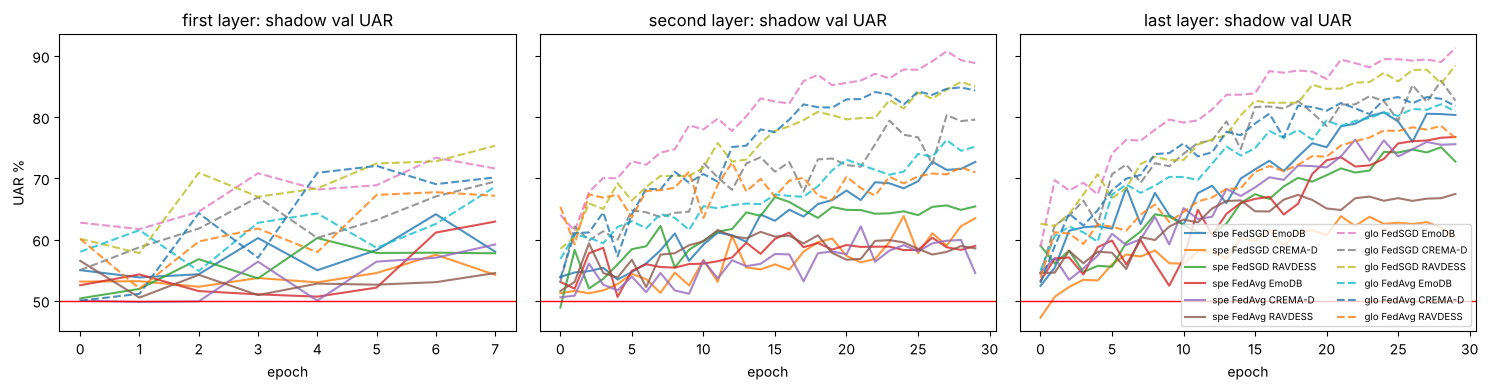

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, layer in zip(axes, LAYERS):
    for norm in NORMS:
        for mode in MODES:
            for dp in DPS:
                f = RES / f'{norm}_norm' / mode / dp / f'attack_train_{layer}.csv'
                if f.exists():
                    h = pd.read_csv(f)
                    ax.plot(h.epoch, 100 * h.uar, ls='-' if norm == 'speaker' else '--', alpha=.8,
                            label=f'{norm[:3]} {MODE[mode]} {NAME[dp]}')
    ax.axhline(50, c='r', lw=1); ax.set_title(f'{layer} layer: shadow val UAR'); ax.set_xlabel('epoch')
axes[0].set_ylabel('UAR %'); axes[2].legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

## 6. Supplementary: same-corpus, speaker-disjoint probe

The shadow data comes from the same corpus as the private data but from different speakers. This tests whether the updates leak gender at all.

,dataset,norm,mode,n_updates,n_speakers,first_uar,second_uar,last_uar
0,CREMA-D,speaker,FedSGD,1400,72,66.47,67.06,64.00
1,CREMA-D,speaker,FedAvg,1400,72,66.08,68.99,68.14
2,CREMA-D,global,FedSGD,1400,72,66.01,63.42,60.90
3,CREMA-D,global,FedAvg,1400,72,70.56,78.19,68.90
4,RAVDESS,speaker,FedSGD,1800,19,56.51,61.20,56.78
5,RAVDESS,speaker,FedAvg,1800,19,59.52,67.91,64.50
6,RAVDESS,global,FedSGD,1800,19,57.21,54.32,52.27
7,RAVDESS,global,FedAvg,1800,19,77.96,79.98,66.98
8,EmoDB,speaker,FedSGD,800,8,55.73,55.74,54.18
9,EmoDB,speaker,FedAvg,800,8,53.37,49.62,48.07


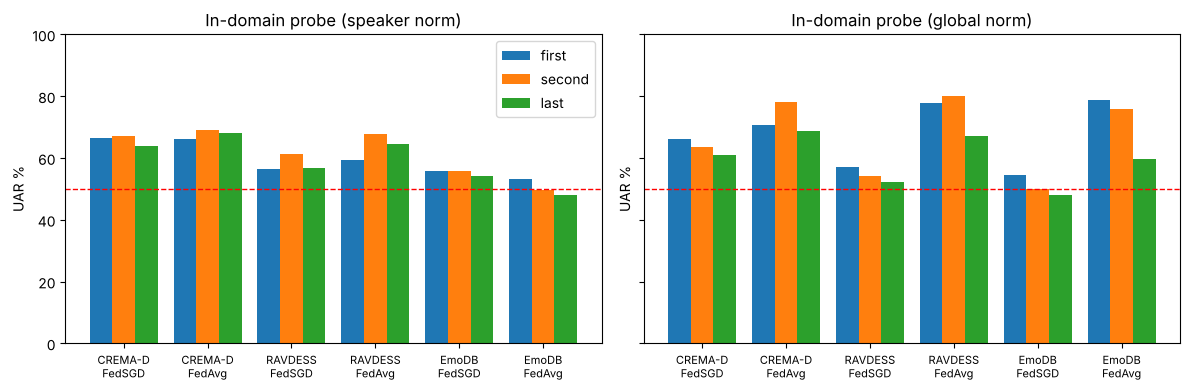

In [9]:
probe = pd.read_csv(RES / 'indomain_probe.csv')
probe[[f'{l}_uar' for l in LAYERS]] *= 100
probe['dataset'] = probe.dataset.map(NAME); probe['mode'] = probe['mode'].map(MODE)
display(probe)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, norm in zip(axes, NORMS):
    p = probe[probe.norm == norm]
    lab = p.dataset + '\n' + p['mode']; x = np.arange(len(p)); w = 0.27
    for k, l in enumerate(LAYERS):
        ax.bar(x + (k - 1) * w, p[f'{l}_uar'], w, label=l)
    ax.axhline(50, ls='--', c='r', lw=1); ax.set_xticks(x, lab, fontsize=8); ax.set_ylim(0, 100)
    ax.set_title(f'In-domain probe ({norm} norm)'); ax.set_ylabel('UAR %')
axes[0].legend(); plt.tight_layout(); plt.show()

## 7. Summary

* **Federated SER reproduces.** FedSGD and FedAvg perform similarly. On CREMA-D our UAR is above the paper's.
* **The cross-corpus gender attack does not reproduce** with our substitute corpora and CPU budget: it stays near chance, against the paper's 74–91%.
* **The updates still leak gender** when the shadow data matches the private corpus. On CREMA-D the first layer gives 66–71% UAR, close to the paper's CREMA-D numbers.
* The likely causes and all other differences are listed in the repository README.